# Chance level C vs I amb Matriu de covariàncies, espai tangent amb Riemann i LDA

**Tres preguntes:**
1. Quants epochs calen (aprox.) per superar el chance level en C vs I?
2. Per a cada elèctrode, a partir de quin instant se supera chance level?
3. A nivell de grup, on i quan podem afirmar que l'accuracy supera chance?

**Metodologia:**
- Surrogate per permutació d'etiquetes, **per subjecte × elèctrode × finestra temporal**.
- ΔAcc = Acc_real(t) − Acc_chance(t)
- Contrast de grup: paired t-test one-tailed vectoritzat + FDR per cel·la (canal, t).
- Paral·lelisme: `joblib.Parallel` (N_JOBS) sobre subjectes.
- Els resultats intermedis amb cost computacional alt es desen a disc per evitar recalcular si el kernel cau.


In [ ]:
import warnings
from pathlib import Path
from scipy.signal import hilbert
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import numpy as np
import pandas as pd
from joblib import Parallel, delayed, cpu_count
from scipy.stats import ttest_rel
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

try:
    from pyriemann.estimation import Covariances
    from pyriemann.tangentspace import TangentSpace
except ImportError:
    !pip install -q pyriemann
    from pyriemann.estimation import Covariances
    from pyriemann.tangentspace import TangentSpace

try:
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    drive = None
    IN_COLAB = False

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")

if IN_COLAB:
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"
    drive.mount("/content/drive")
else:
    DRIVE_ROOT = Path(r"H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"

BASE_DIR = PROJECT_DIR
DATA_DIR = PROJECT_DIR / "02_Data" / "01_Preprocessed_epochs"
ANALYSIS_ROOT = PROJECT_DIR / "04_Anàlisi"
ANALYSIS_DIR = ANALYSIS_ROOT / "c_vs_i_riemann"
CACHE_DIR = ANALYSIS_DIR / "cache"
TABLES_DIR = ANALYSIS_DIR / "tables"
FIGURES_DIR = ANALYSIS_DIR / "figures"
for folder in (DATA_DIR, ANALYSIS_ROOT, ANALYSIS_DIR, CACHE_DIR, TABLES_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_FILES = sorted(DATA_DIR.glob("*.fif"))

COND_EVENTS = {
    "Congruent": ["event_1", "event_2"],
    "Incongruent": ["event_3", "event_4", "event_5", "event_6", "event_7", "event_8"],
}

print(f"Entorn: {'Colab' if IN_COLAB else 'Local'}")
print(f"Projecte: {PROJECT_DIR}")
print(f"Dades: {DATA_DIR}")
print(f"Resultats: {ANALYSIS_DIR}")
print(f"Fitxers .fif trobats: {len(DATA_FILES)}")
print(f"Cores disponibles: {cpu_count()}")

Entorn: Local
Projecte: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Dades: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Resultats: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_riemann
Fitxers .fif trobats: 47
Cores disponibles: 8


## Configuració

In [5]:
TASK_TAG = "c_vs_i_riemann"
RECALCULAR_CHANCE_LEVEL = False
ANALYSIS_WINDOW = (0.5, 1.5)

# Regions d'interès (clústers) per banda
TARGET_BANDS_CLUSTERS = {
    "theta": ["FCz", "Fz", "Cz"],
    "alpha": ["Oz", "P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "O2"],
}

BAND_RANGES = {
    "theta": (5.0, 7.0),
    "alpha": (8.0, 12.0),
}
CHANNEL_MODE = list(TARGET_BANDS_CLUSTERS.keys())

# Subjectes: sempre des de CSV, i retallats amb MAX_SUBJECTS
SELECTED_SUBJECTS_CSV = PROJECT_DIR / "04_Anàlisi" / "01_exploracio" / "tables" / "subjectes_seleccionats.csv"
MAX_SUBJECTS = 12  # None = tots els del CSV
UNDERSAMPLE_CLASSES = True  # balanceja C/I per subjecte

# Directoris de sortida
RESULTS_DIR = ANALYSIS_DIR
CACHE_EPOCHS_DIR = CACHE_DIR
CACHE_MAP_FILE = CACHE_DIR / f"tensors_map_{TASK_TAG}.npz"
EPOCHS_CSV = TABLES_DIR / "epochs_grid_riemann.csv"
ONSET_CSV = TABLES_DIR / "onset_summary_riemann.csv"

# Mapa temps×elèctrode
MAP_WINDOW_SEC = 0.500  # amplada finestra temporal (s)
MAP_STEP_SEC = 0.05  # pas (s) - incrementat lleugerament per eficiència temporal
MAP_CV_MAX_SPLITS = 3

# Surrogate
N_PERM_SURROGATE = 200

# Graella epochs
EPOCHS_GRID = [x for x in range(20, 200, 20)]
N_REPEATS_EPOCHS = 10
N_JOBS = 6

RANDOM_SEED = 42

print(f"BASE_DIR: {BASE_DIR}")
print(f"ANALYSIS_ROOT: {ANALYSIS_ROOT}")
print(f"RESULTS_DIR: {RESULTS_DIR}")
print(f"CACHE_DIR: {CACHE_DIR}")
print(f"TABLES_DIR: {TABLES_DIR}")
print(f"FIGURES_DIR: {FIGURES_DIR}")
print(f"SELECTED_SUBJECTS_CSV: {SELECTED_SUBJECTS_CSV}")
print(f"TARGET_BANDS_CLUSTERS: {TARGET_BANDS_CLUSTERS}")
print(f"BAND_RANGES: {BAND_RANGES}")

BASE_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
ANALYSIS_ROOT: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi
RESULTS_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_riemann
CACHE_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_riemann\cache
TABLES_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_riemann\tables
FIGURES_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_riemann\figures
SELECTED_SUBJECTS_CSV: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\subjectes_seleccionats.csv
TARGET_BANDS_CLUSTERS: {'theta': ['FCz', 'Fz', 'Cz'], 'alpha': ['Oz', 'P7', 'P8', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'O2']}
BAND_RANGES: {'theta': (5.0, 7.0), 'alpha': (8.0, 12.

## 1 · Càrrega de dades

In [ ]:
def load_chance_epochs():
    """Carrega els subjectes, filtra les bandes i selecciona els clústers de canals requerits."""
    df_sel = pd.read_csv(SELECTED_SUBJECTS_CSV)

    subject_ids = df_sel["subjecte"].dropna().astype(str).tolist()
    subject_ids = list(dict.fromkeys(subject_ids))
    if MAX_SUBJECTS is not None:
        subject_ids = subject_ids[:MAX_SUBJECTS]
    print(f"Subjectes seleccionats a carregar: {len(subject_ids)}")

    fif_by_subject = {p.stem: p for p in DATA_FILES}

    # Estructura: X_blocks["theta"] = [(trials, channels, times), ...], etc.
    X_blocks = {band: [] for band in TARGET_BANDS_CLUSTERS}
    y_blocks = []
    subj_blocks = []
    skipped = []

    # Store dynamic channel names available per band
    avail_ch_names = {band: [] for band in TARGET_BANDS_CLUSTERS}
    first_subject_times = None

    for subj_name in subject_ids:
        fif_path = fif_by_subject.get(subj_name)
        if fif_path is None:
            skipped.append(f"{subj_name}: fitxer .fif no trobat")
            continue

        ep = mne.read_epochs(fif_path, preload=True)

        for ch_idx, ch_name in enumerate(ep.ch_names):
            if ep.info["chs"][ch_idx]["unit"] == 0:
                ep.info["chs"][ch_idx]["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
                ep.info["chs"][ch_idx]["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE

        ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")
        ep = ep.copy().pick(mne.pick_types(ep.info, eeg=True))

        c_names = [n for n in COND_EVENTS["Congruent"] if n in ep.event_id]
        i_names = [n for n in COND_EVENTS["Incongruent"] if n in ep.event_id]
        ep = ep[c_names + i_names].copy().crop(tmin=ANALYSIS_WINDOW[0], tmax=ANALYSIS_WINDOW[1])

        if first_subject_times is None:
            first_subject_times = np.array(ep.times, dtype=np.float32)

        events = ep.events[:, 2]
        c_codes = [ep.event_id[n] for n in c_names]
        y_s = np.where(np.isin(events, c_codes), 0, 1).astype(np.int8)

        n_c, n_i = int((y_s == 0).sum()), int((y_s == 1).sum())
        if min(n_c, n_i) == 0:
            skipped.append(f"{fif_path.name}: classe buida (C={n_c}, I={n_i})")
            continue

        if UNDERSAMPLE_CLASSES:
            n_min = min(n_c, n_i)
            rng = np.random.default_rng(RANDOM_SEED + sum(bytearray(subj_name.encode("utf-8"))))
            idx_c = np.where(y_s == 0)[0]
            idx_i = np.where(y_s == 1)[0]
            keep_idx = np.concatenate(
                [rng.choice(idx_c, n_min, replace=False), rng.choice(idx_i, n_min, replace=False)]
            )
            rng.shuffle(keep_idx)
            ep = ep[keep_idx]
            y_s = y_s[keep_idx]

        valid_for_subject = True
        subj_band_data = {}
        for band, target_channels in TARGET_BANDS_CLUSTERS.items():
            avail_chs = [ch for ch in target_channels if ch in ep.ch_names]
            if len(avail_chs) < len(target_channels) * 0.5:  # Require at least half the cluster
                skipped.append(f"{fif_path.name}: massa pocs canals per al cluster {band}")
                valid_for_subject = False
                break

            avail_ch_names[band] = avail_chs

            l_freq, h_freq = BAND_RANGES[band]
            ep_band = ep.copy().pick(avail_chs)
            ep_band._data = np.ascontiguousarray(ep_band._data)
            ep_band.filter(
                l_freq=l_freq,
                h_freq=h_freq,
                method="fir",
                phase="zero-double",
                verbose=False,
            )
            subj_band_data[band] = ep_band.get_data().astype(np.float32)

        if not valid_for_subject:
            continue

        for band in TARGET_BANDS_CLUSTERS:
            X_blocks[band].append(subj_band_data[band])

        y_blocks.append(y_s)
        subj_blocks.extend([subj_name] * len(y_s))

    X_dict = {band: np.concatenate(blocks, axis=0) for band, blocks in X_blocks.items()}
    y = np.concatenate(y_blocks, axis=0)
    subj_list = np.array(subj_blocks, dtype=object)

    print(f"Mostres totals: {len(y)} | C={(y==0).sum()} | I={(y==1).sum()}")
    print(f"Subjectes carregats: {len(np.unique(subj_list))}")
    for band in TARGET_BANDS_CLUSTERS:
        print(f"Canals clúster {band}: {avail_ch_names[band]}")

    if skipped:
        print("Omesos:")
        for m in skipped:
            print(f"  {m}")

    return X_dict, y, subj_list, avail_ch_names, first_subject_times


X_dict, y, subj_list, ch_names_dict, times = load_chance_epochs()

Subjectes seleccionats a carregar: 12
Mostres totals: 4784 | C=2392 | I=2392
Subjectes carregats: 12
Canals clúster theta: ['FCz', 'Fz', 'Cz']
Canals clúster alpha: ['Oz', 'P7', 'P8', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'O2']


In [ ]:
# Verificació ràpida dimensions i distribució de subj_list
for band, ch_names in ch_names_dict.items():
    print(f"Canals disponibles per {band}: {ch_names}")

for band, X in X_dict.items():
    print(f"{band} - shape: {X.shape}, dtype: {X.dtype}, min: {X.min():.3e}, max: {X.max():.3e}")

for subj in np.unique(subj_list):
    count = np.sum(subj_list == subj)
    print(f"  {subj}: {count} mostres")

Canals disponibles per theta: ['FCz', 'Fz', 'Cz']
Canals disponibles per alpha: ['Oz', 'P7', 'P8', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'O2']
theta - shape: (4784, 3, 501), dtype: float32, min: -4.717e+01, max: 4.660e+01
alpha - shape: (4784, 10, 501), dtype: float32, min: -6.131e+01, max: 6.156e+01
  P003: 382 mostres
  P011: 242 mostres
  P017: 408 mostres
  P022: 368 mostres
  P023: 498 mostres
  P024: 310 mostres
  P030: 464 mostres
  P044: 404 mostres
  P051: 378 mostres
  P053: 304 mostres
  P057: 516 mostres
  P058: 510 mostres


## 2 · Funcions de CV i surrogate

### Decisions de disseny

**Per quin nivell es calcula el surrogate?**  
El surrogate s'avalua **a la mateixa finestra temporal** que l'accuracy real.  
D'aquesta manera, ΔAcc(t) = Acc_real(t) − Acc_chance(t) és una comparació neta:
ambdues xifres es basen en les mateixes mostres temporals i el mateix classificador.

**Quantes permutacions?**  
`N_PERM_SURROGATE` (configurable a la cel·la 1). Per a inferència final usa ≥200; per a
proves ràpides, 50 és acceptable.

**Paired t-test de grup:**  
Per a cada cel·la (canal, t) comparem el vector d'Acc_real dels subjectes vs el vector
d'Acc_chance. Amb N≥6 subjectes vàlids, el test t aparellat és adequat.  
Criteri robust final: p < 0.05 **i** ΔAcc_grupal > 0 **i** hit-rate ≥ 0.5.


In [ ]:
def choose_n_splits(y_s, max_splits=5):
    """Folds CV en funció del mínim de la classe menys freqüent."""
    return max(2, min(max_splits, int(np.bincount(y_s).min())))


def make_clf():
    # Pipeline Riemann + Shrinkage LDA
    # Calculant matrius de covariància amb OAS, espai tangent i classicació amb regularització espacial.
    return make_pipeline(
        Covariances(estimator="oas"),
        TangentSpace(metric="riemann"),
        LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"),
    )


def cv_accuracy(X_feat, y_s, n_splits, seed=RANDOM_SEED):
    """Accuracy mitjana en CV estratificat.
    X_feat: (n_trials, n_channels, n_times)
    """
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    clf = make_clf()
    accs = []

    # pyriemann expect (n_trials, n_channels, n_times)
    for tr, te in cv.split(X_feat, y_s):
        clf.fit(X_feat[tr], y_s[tr])
        accs.append(float(np.mean(clf.predict(X_feat[te]) == y_s[te])))
    return float(np.mean(accs))


def surrogate_distribution(X_feat, y_s, n_splits, n_perm, seed=RANDOM_SEED):
    """Distribució surrogate per permutació d'etiquetes.
    Retorna array de shape (n_perm,) amb les accuracies permutades.
    """
    rng = np.random.default_rng(seed)
    perm_accs = np.empty(n_perm, dtype=np.float32)
    for p in range(n_perm):
        y_perm = rng.permutation(y_s)
        perm_accs[p] = cv_accuracy(X_feat, y_perm, n_splits, seed=seed + p + 1)
    return perm_accs


def balanced_sample(y_s, n_total, rng):
    """Retorna índexs balancejats (n_total//2 per classe) o None si no hi ha prou."""
    n2 = n_total // 2
    idx_c = np.where(y_s == 0)[0]
    idx_i = np.where(y_s == 1)[0]
    if len(idx_c) < n2 or len(idx_i) < n2:
        return None
    out = np.concatenate([rng.choice(idx_c, n2, replace=False), rng.choice(idx_i, n2, replace=False)])
    rng.shuffle(out)
    return out

## 3 · Worker per subjecte (paral·lelitzat)

La funció `_process_subject` encapsula **tot el treball** d'un subjecte:

1. Per a cada finestra temporal, calcula Acc_real i la distribució surrogate **a la mateixa finestra**.
2. Retorna `real_arr[ch, t]`, `chance_mean_arr[ch, t]`, `chance_q95_arr[ch, t]`.

Desacoblar el surrogate per finestra és la **clau de la correctesa**:
usar un surrogate global (finestra completa) com a baseline per finestres individuals
seria inconsistent si la senyalització varia molt al llarg del temps.


In [8]:
def _process_subject(si, subj, X_dict, y_all, subj_list_all, band_names, starts, stops):
    """Processa un subjecte: per a cada (banda, finestra) calcula
    acc_real i la distribució surrogate. Ara la 'banda' fa referència al clúster.»"""
    idx_s = np.where(subj_list_all == subj)[0]
    ys = y_all[idx_s]

    n_bands = len(band_names)
    n_w = len(starts)

    real_arr = np.full((n_bands, n_w), np.nan, dtype=np.float32)
    surr_mean = np.full((n_bands, n_w), np.nan, dtype=np.float32)
    surr_q95 = np.full((n_bands, n_w), np.nan, dtype=np.float32)

    if len(np.unique(ys)) < 2:
        return real_arr, surr_mean, surr_q95

    n_splits = choose_n_splits(ys, max_splits=MAP_CV_MAX_SPLITS)
    base_seed = RANDOM_SEED + 10_000 * (si + 1)

    for b_idx, band in enumerate(band_names):
        Xs_band = X_dict[band][idx_s]  # shape: (trials, channels, times)
        for wi, (s, e) in enumerate(zip(starts, stops)):
            # Tallem la finestra temporal mantenint tots els canals d'aquest cluster
            X_feat = Xs_band[:, :, s:e]

            win_seed = base_seed + wi * 1000 + b_idx
            real_arr[b_idx, wi] = cv_accuracy(X_feat, ys, n_splits, seed=win_seed)
            dist = surrogate_distribution(X_feat, ys, n_splits, n_perm=min(N_PERM_SURROGATE, 500), seed=win_seed + 1)
            surr_mean[b_idx, wi] = float(dist.mean())
            surr_q95[b_idx, wi] = float(np.quantile(dist, 0.95))

    return real_arr, surr_mean, surr_q95

## 4 · Quants epochs calen per superar chance? (graella)

Aquí la feature és la sèrie temporal completa (`ANALYSIS_WINDOW`) de cada canal,
i es submostregen n_epochs balancejats per estudiar com evoluciona l'accuracy.

El surrogate es calcula **a la mateixa submostra** per ser consistent.


In [9]:
def _epochs_worker(si, subj, X_dict, y_all, subj_list_all, band_names):
    """Per a un subjecte, recorre EPOCHS_GRID × clústers i calcula
    acc_real_mean, chance_mean, chance_q95 amb submostreig repetit."""
    idx_s = np.where(subj_list_all == subj)[0]
    ys = y_all[idx_s]

    if len(np.unique(ys)) < 2:
        return []

    rows = []
    rng = np.random.default_rng(RANDOM_SEED + si * 9973)
    n_splits = choose_n_splits(ys, max_splits=MAP_CV_MAX_SPLITS)

    for b_idx, band in enumerate(band_names):
        Xs_band = X_dict[band][idx_s]
        for n_total in EPOCHS_GRID:
            if n_total % 2 != 0:
                continue
            real_accs = []
            perm_all = []

            for rep in range(N_REPEATS_EPOCHS):
                idx_sub = balanced_sample(ys, n_total, rng)
                if idx_sub is None:
                    continue

                X_feat = Xs_band[idx_sub]  # Shape (trials_sub, channels, times)

                seed_r = RANDOM_SEED + si * 9973 + b_idx * 997 + n_total + rep
                real_accs.append(cv_accuracy(X_feat, ys[idx_sub], n_splits, seed=seed_r))
                perm_dist = surrogate_distribution(
                    X_feat,
                    ys[idx_sub],
                    n_splits,
                    n_perm=max(50, N_PERM_SURROGATE // 10),
                    seed=seed_r + 1,
                )
                perm_all.append(perm_dist)

            if not real_accs:
                continue
            perm_concat = np.concatenate(perm_all) if perm_all else np.array([0.5])

            rows.append(
                {
                    "subject": subj,
                    "electrode": band,
                    "n_epochs_total": int(n_total),
                    "acc_real_mean": float(np.mean(real_accs)),
                    "acc_real_std": float(np.std(real_accs)),
                    "acc_chance_mean": float(perm_concat.mean()),
                    "acc_chance_q95": float(np.quantile(perm_concat, 0.95)),
                    "delta_acc": float(np.mean(real_accs) - perm_concat.mean()),
                    "delta_acc_q95": float(np.mean(real_accs) - np.quantile(perm_concat, 0.95)),
                }
            )
    return rows

### 4a Execució (paral·lel per subjectes)

In [11]:
subject_ids = pd.unique(subj_list).tolist()

CACHE_EPOCHS = CACHE_EPOCHS_DIR / (
    f"epochs_grid_{TASK_TAG}_sub{MAX_SUBJECTS if MAX_SUBJECTS is not None else 'all'}.csv"
)

if not RECALCULAR_CHANCE_LEVEL and CACHE_EPOCHS.exists():
    print(f"Carregant df_epochs des de cache: {CACHE_EPOCHS}")
    df_epochs = pd.read_csv(CACHE_EPOCHS)
else:
    print(
        f"Graella epochs — {len(subject_ids)} subj × {len(CHANNEL_MODE)} clústers × "
        f"{len(EPOCHS_GRID)} punts × {N_REPEATS_EPOCHS} reps …"
    )

    all_rows = Parallel(n_jobs=N_JOBS, verbose=5)(
        delayed(_epochs_worker)(si, subj, X_dict, y, subj_list, CHANNEL_MODE) for si, subj in enumerate(subject_ids)
    )

    df_epochs = (
        pd.DataFrame([r for rows in all_rows for r in rows])
        .sort_values(["subject", "electrode", "n_epochs_total"])
        .reset_index(drop=True)
    )

    df_epochs.to_csv(CACHE_EPOCHS, index=False)
    print(f"Desat cache: {CACHE_EPOCHS}")

df_epochs.to_csv(EPOCHS_CSV, index=False)
print(f"Desat taula: {EPOCHS_CSV}")
df_epochs.head(10)

Carregant df_epochs des de cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_riemann\cache\epochs_grid_c_vs_i_riemann_sub12.csv
Desat taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_riemann\tables\epochs_grid_riemann.csv


,subject,electrode,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95,delta_acc,delta_acc_q95
0,P003,alpha,20,0.545000,0.154029,0.496750,0.700000,0.048250,-0.155000
1,P003,alpha,40,0.637500,0.077661,0.500650,0.675000,0.136850,-0.037500
2,P003,alpha,60,0.666667,0.066667,0.498933,0.633333,0.167733,0.033333
3,P003,alpha,80,0.638750,0.066250,0.501400,0.612500,0.137350,0.026250
4,P003,alpha,100,0.625000,0.060539,0.500690,0.610000,0.124310,0.015000
5,P003,alpha,120,0.667500,0.042238,0.501217,0.591667,0.166283,0.075833
6,P003,alpha,140,0.647857,0.019180,0.499050,0.578928,0.148807,0.068929
7,P003,alpha,160,0.650625,0.031181,0.495825,0.575000,0.154800,0.075625
8,P003,alpha,180,0.659444,0.041726,0.502222,0.583333,0.157222,0.076111
9,P003,theta,20,0.535000,0.128550,0.491200,0.700000,0.043800,-0.165000


In [12]:
# Mostrar df_epochs ordenats per delta_acc_q95 descendent
df_epochs_sorted = df_epochs.sort_values("delta_acc_q95", ascending=False).reset_index(drop=True)
display(df_epochs_sorted.head(10**6))

,subject,electrode,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95,delta_acc,delta_acc_q95
0,P058,alpha,120,0.691667,0.052308,0.501525,0.591667,0.190142,0.100000
1,P058,alpha,180,0.675000,0.043973,0.496500,0.577778,0.178500,0.097222
2,P057,alpha,160,0.656250,0.036657,0.497862,0.575000,0.158388,0.081250
3,P057,alpha,180,0.653333,0.027465,0.497900,0.572222,0.155433,0.081111
4,P058,alpha,160,0.659375,0.034939,0.497831,0.581250,0.161544,0.078125
...,...,...,...,...,...,...,...,...,...
211,P051,alpha,20,0.465000,0.150083,0.499550,0.702499,-0.034550,-0.237499
212,P023,theta,20,0.450000,0.170294,0.491250,0.700000,-0.041250,-0.250000
213,P024,alpha,20,0.475000,0.130863,0.503300,0.750000,-0.028300,-0.275000
214,P053,alpha,20,0.465000,0.136107,0.502600,0.750000,-0.037600,-0.285000


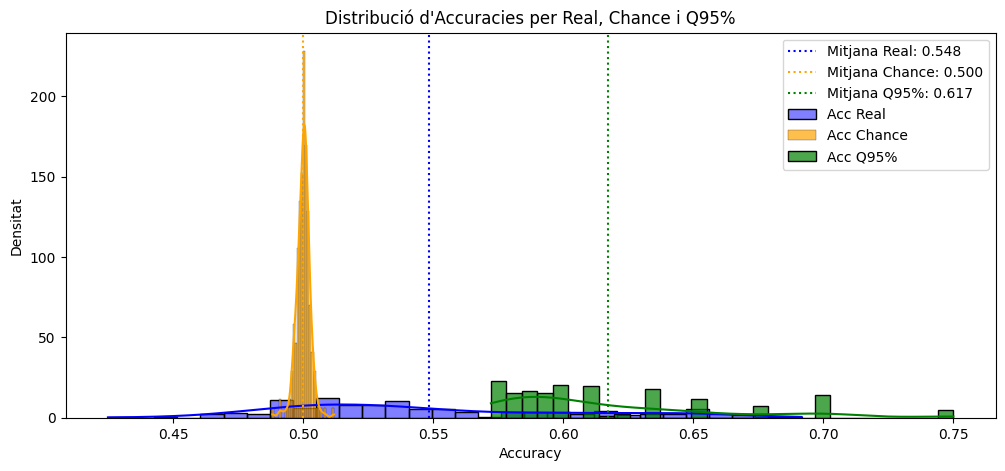

In [13]:
# Histograma acc_real_mean, acc_chance_mean i acc_chance_q95 amb seaborn
plt.figure(figsize=(12, 5))
sns.histplot(df_epochs, x="acc_real_mean", color="blue", label="Acc Real", kde=True, stat="density", bins=30)
sns.histplot(
    df_epochs, x="acc_chance_mean", color="orange", label="Acc Chance", kde=True, stat="density", bins=30, alpha=0.7
)
sns.histplot(
    df_epochs, x="acc_chance_q95", color="green", label="Acc Q95%", kde=True, stat="density", bins=30, alpha=0.7
)
plt.title("Distribució d'Accuracies per Real, Chance i Q95%")
plt.xlabel("Accuracy")
plt.ylabel("Densitat")
# Ensenya mitjanes dels tres grups
mean_real = df_epochs["acc_real_mean"].mean()
mean_chance = df_epochs["acc_chance_mean"].mean()
mean_q95 = df_epochs["acc_chance_q95"].mean()

plt.axvline(mean_real, color="blue", linestyle=":", label=f"Mitjana Real: {mean_real:.3f}")
plt.axvline(mean_chance, color="orange", linestyle=":", label=f"Mitjana Chance: {mean_chance:.3f}")
plt.axvline(mean_q95, color="green", linestyle=":", label=f"Mitjana Q95%: {mean_q95:.3f}")
plt.legend()
plt.savefig(FIGURES_DIR / f"histogram_epochs_{TASK_TAG}.png")
plt.show()

### 4b · Resum numèric epochs → accuracy (sense figures)

Aquesta cel·la deixa només el resum numèric de la graella.
Totes les figures queden centralitzades a l'apartat 7.

In [14]:
# Resum numèric de la graella d'epochs
grp = (
    df_epochs.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
    )
    .reset_index()
)

df_surpass = df_epochs[df_epochs["acc_real_mean"] > df_epochs["acc_chance_q95"]]

print("Resum de rendiment (graella epochs):")
print(f"- Files totals: {len(df_epochs)}")
print(f"- Subjectes únics: {df_epochs['subject'].nunique()}")
print(f"- Elèctrodes únics: {df_epochs['electrode'].nunique()}")
print(f"- n_epochs provats: {sorted(df_epochs['n_epochs_total'].unique().tolist())}")
print(f"- Acc real mitjana global: {df_epochs['acc_real_mean'].mean():.4f}")
print(f"- Chance q95 mitjana global: {df_epochs['acc_chance_q95'].mean():.4f}")

if not df_surpass.empty:
    print(f"- Mínim d'epochs per superar q95: {int(df_surpass['n_epochs_total'].min())}")
    print(
        f"- Combinacions que superen q95: {len(df_surpass)}/{len(df_epochs)} "
        f"({100*len(df_surpass)/len(df_epochs):.1f}%)"
    )
else:
    print("- Cap combinació supera el chance q95 en la graella actual.")

display(grp.head(10))

Resum de rendiment (graella epochs):
- Files totals: 216
- Subjectes únics: 12
- Elèctrodes únics: 2
- n_epochs provats: [20, 40, 60, 80, 100, 120, 140, 160, 180]
- Acc real mitjana global: 0.5485
- Chance q95 mitjana global: 0.6173
- Mínim d'epochs per superar q95: 60
- Combinacions que superen q95: 38/216 (17.6%)


,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95
0,20,0.526875,0.145515,0.499535,0.712812
1,40,0.547708,0.087900,0.501006,0.659583
2,60,0.549306,0.073100,0.500094,0.632639
3,80,0.544010,0.059203,0.499814,0.613021
4,100,0.551292,0.059350,0.500358,0.602500
5,120,0.551424,0.047679,0.499906,0.593750
6,140,0.555030,0.046305,0.499935,0.584866
7,160,0.554427,0.040785,0.499875,0.579948
8,180,0.556296,0.039549,0.500272,0.576400


## 5 · Mapa temps×elèctrode (càlcul paral·lel)

### Nota sobre les features per finestra
Cada finestra de `MAP_WINDOW_SEC` és classificada usant **tots els punts temporals
de la finestra** com a features (matriu `trials × win_samples` al LR).
Això és molt més informatiu que usar la mitjana (1 feature), però augmenta el
cost computacional — d'aquí la necessitat del paral·lelisme.


In [15]:
subject_ids = pd.unique(subj_list).tolist()

# Defineix finestres temporals
time_step = float(np.median(np.diff(times)))
sfreq_est = 1.0 / time_step
win_samples = max(2, int(round(MAP_WINDOW_SEC * sfreq_est)))
step_samples = max(1, int(round(MAP_STEP_SEC * sfreq_est)))

starts = np.arange(0, len(times) - win_samples + 1, step_samples)
stops = starts + win_samples
window_centers = np.array([times[s:e].mean() for s, e in zip(starts, stops)], dtype=np.float32)
n_w, n_bands = len(window_centers), len(CHANNEL_MODE)

print(f"Finestres: {n_w} | amplada={MAP_WINDOW_SEC*1000:.0f}ms, pas={MAP_STEP_SEC*1000:.0f}ms")
print(f"Clústers (Bandes): {n_bands} | Subjectes: {len(subject_ids)}")
print(f"Features: covariància sobre cadascuna de les mostres de la finestra.")
print(
    f"Total de surrogates a calcular: {len(subject_ids)} × {n_bands} × {n_w} × {N_PERM_SURROGATE:,} = "
    f"{len(subject_ids)*n_bands*n_w*N_PERM_SURROGATE:,}"
)

Finestres: 11 | amplada=500ms, pas=50ms
Clústers (Bandes): 2 | Subjectes: 12
Features: covariància sobre cadascuna de les mostres de la finestra.
Total de surrogates a calcular: 12 × 2 × 11 × 200 = 52,800


In [16]:
subject_ids = pd.unique(subj_list).tolist()

print("Executant mapa temps×clúster (paral·lel per subjectes) …")
print(f"Subjectes: {len(subject_ids)}")

if not RECALCULAR_CHANCE_LEVEL and CACHE_MAP_FILE.exists():
    print(f"Carregant mapa temps×clúster des de cache: {CACHE_MAP_FILE}")
    map_data = np.load(CACHE_MAP_FILE)
    real_map = map_data["real_map"]
    surr_mean = map_data["surr_mean"]
    surr_q95 = map_data["surr_q95"]
else:
    print("Recalculant mapa temps×clúster (permutacions) …")
    results = Parallel(n_jobs=N_JOBS)(
        delayed(_process_subject)(si, subj, X_dict, y, subj_list, CHANNEL_MODE, starts, stops)
        for si, subj in enumerate(subject_ids)
    )

    # Reassembla tensors (n_subj, n_bands, n_w)
    real_map = np.stack([r[0] for r in results], axis=0)  # (S, C, W)
    surr_mean = np.stack([r[1] for r in results], axis=0)
    surr_q95 = np.stack([r[2] for r in results], axis=0)
    np.savez_compressed(CACHE_MAP_FILE, real_map=real_map, surr_mean=surr_mean, surr_q95=surr_q95)
    print(f"Desat mapa temps×clúster a cache: {CACHE_MAP_FILE}")

delta_map = real_map - surr_mean  # ΔAcc(s, ch, t)
above_q95_map = real_map > surr_q95  # bool(s, ch, t)

print(f"Tensors shape: real_map={real_map.shape}  (subj, clúster, finestra)")

Executant mapa temps×clúster (paral·lel per subjectes) …
Subjectes: 12
Carregant mapa temps×clúster des de cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_riemann\cache\tensors_map_c_vs_i_riemann.npz
Tensors shape: real_map=(12, 2, 11)  (subj, clúster, finestra)


## 6 · Estadística de grup: paired t-test per cel·la (canal, t)

Per a cada cel·la $(ch, t)$ comparem:
- **real_map[:, ch, t]**: accuracy real de cada subjecte
- **surr_mean[:, ch, t]**: accuracy de chance (surrogate mean) del mateix subjecte

Hipòtesi H₁ (one-tailed): Acc_real > Acc_chance → només p/2 si t > 0.
Criteri final robust: `p < 0.05` **i** `ΔAcc_grupal > 0` **i** `hit-rate ≥ 0.50`.


In [17]:
n_subj_arr = real_map.shape[0]
p_map = np.full((n_bands, n_w), np.nan, dtype=np.float64)
t_map = np.full((n_bands, n_w), np.nan, dtype=np.float64)

for b_idx in range(n_bands):
    for wi in range(n_w):
        a = real_map[:, b_idx, wi]
        b = surr_mean[:, b_idx, wi]
        valid = ~np.isnan(a) & ~np.isnan(b)
        if valid.sum() < 6:
            continue
        t_stat, p_two = ttest_rel(a[valid], b[valid])
        t_map[b_idx, wi] = t_stat
        # One-tailed: p/2 si t > 0 (direccional: real > chance)
        p_map[b_idx, wi] = (p_two / 2) if t_stat > 0 else 1.0

mean_delta_map = np.nanmean(delta_map, axis=0)  # (n_bands, n_w)
hit_rate_map = np.nanmean(above_q95_map.astype(float), axis=0)

sig_map = (p_map < 0.05) & (mean_delta_map > 0)

# Onset per clúster: primer instant amb superació significativa
onset_time_per_ch = np.full(n_bands, np.nan, dtype=np.float32)
for b_idx in range(n_bands):
    sig_idx = np.where(sig_map[b_idx])[0]
    if len(sig_idx) > 0:
        onset_time_per_ch[b_idx] = float(window_centers[sig_idx[0]])

# Criteri robust: p<0.05 + ΔAcc>0 + hit-rate≥0.5
robust_map = sig_map & (hit_rate_map >= 0.50)

n_sig = int(np.sum(sig_map))
n_rob = int(np.sum(robust_map))
print(f"Cel·les significatives (p<0.05, ΔAcc>0): {n_sig} / {n_bands*n_w}")
print(f"Cel·les robustes (+hit-rate≥0.5):         {n_rob} / {n_bands*n_w}")

Cel·les significatives (p<0.05, ΔAcc>0): 18 / 22
Cel·les robustes (+hit-rate≥0.5):         11 / 22


## 7 · Visualitzacions (centralitzades)

Totes les figures del notebook es concentren aquí:
- distribucions globals
- corbes epochs→accuracy
- comparativa FCz-theta vs Oz-alpha
- dinàmica temporal i taxa de superació de q95

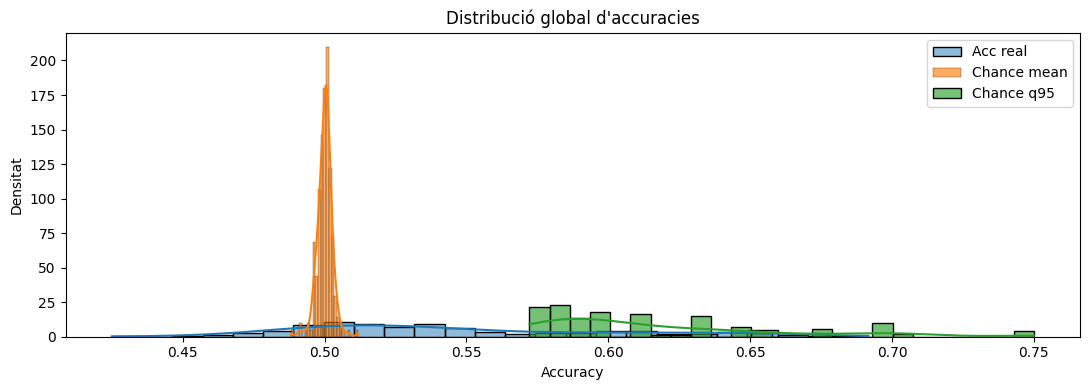

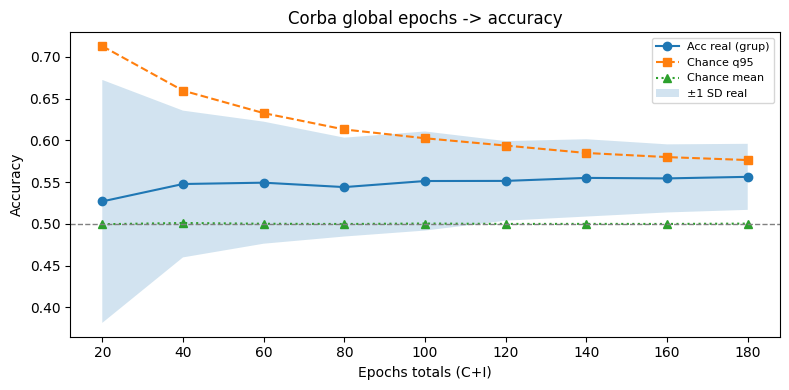

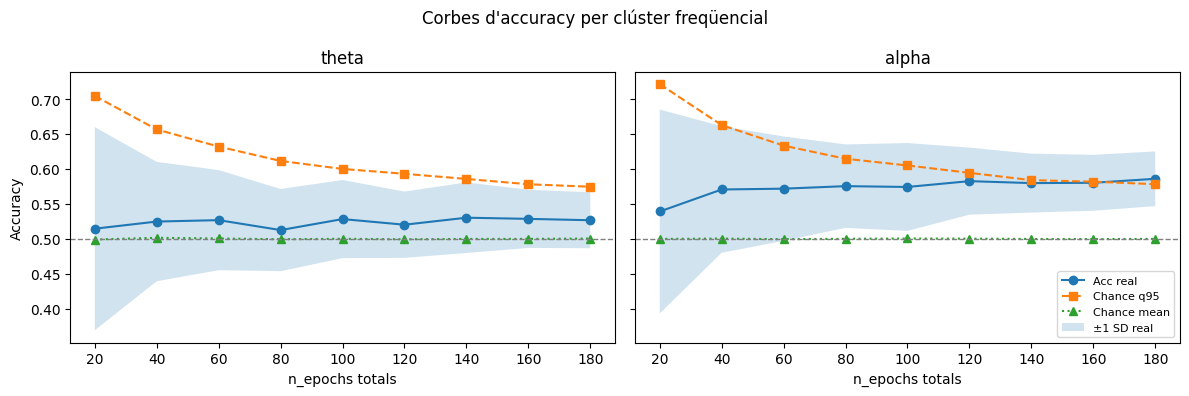

In [18]:
target_electrodes = list(TARGET_BANDS_CLUSTERS.keys())
df_two = df_epochs[df_epochs["electrode"].isin(target_electrodes)].copy()

if df_two.empty:
    raise RuntimeError("No hi ha files de df_epochs per als clústers especificats.")

# 7a) Distribucions globals (real vs chance)
plt.figure(figsize=(11, 4))
sns.histplot(df_epochs, x="acc_real_mean", color="tab:blue", label="Acc real", kde=True, stat="density", bins=25)
sns.histplot(
    df_epochs,
    x="acc_chance_mean",
    color="tab:orange",
    label="Chance mean",
    kde=True,
    stat="density",
    bins=25,
    alpha=0.65,
)
sns.histplot(
    df_epochs,
    x="acc_chance_q95",
    color="tab:green",
    label="Chance q95",
    kde=True,
    stat="density",
    bins=25,
    alpha=0.65,
)
plt.title("Distribució global d'accuracies")
plt.xlabel("Accuracy")
plt.ylabel("Densitat")
plt.legend()
plt.tight_layout()
plt.show()

# 7b) Corba epochs -> accuracy (grup)
grp = (
    df_epochs.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
    )
    .reset_index()
)

plt.figure(figsize=(8, 4))
plt.plot(grp["n_epochs_total"], grp["acc_real_mean"], "o-", label="Acc real (grup)")
plt.plot(grp["n_epochs_total"], grp["acc_chance_q95"], "s--", label="Chance q95")
plt.plot(grp["n_epochs_total"], grp["acc_chance_mean"], "^:", label="Chance mean")
plt.fill_between(
    grp["n_epochs_total"],
    grp["acc_real_mean"] - grp["acc_real_std"],
    grp["acc_real_mean"] + grp["acc_real_std"],
    alpha=0.2,
    label="±1 SD real",
)
plt.axhline(0.5, linestyle="--", color="gray", linewidth=1)
plt.xlabel("Epochs totals (C+I)")
plt.ylabel("Accuracy")
plt.title("Corba global epochs -> accuracy")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 7c) Corbes per electròde (només FCz-theta i Oz-alpha)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, elec in zip(axes, target_electrodes):
    d = df_two[df_two["electrode"] == elec]
    g = (
        d.groupby("n_epochs_total")
        .agg(
            acc_real_mean=("acc_real_mean", "mean"),
            acc_real_std=("acc_real_std", "mean"),
            acc_chance_q95=("acc_chance_q95", "mean"),
            acc_chance_mean=("acc_chance_mean", "mean"),
        )
        .reset_index()
    )

    ax.plot(g["n_epochs_total"], g["acc_real_mean"], "o-", label="Acc real")
    ax.plot(g["n_epochs_total"], g["acc_chance_q95"], "s--", label="Chance q95")
    ax.plot(g["n_epochs_total"], g["acc_chance_mean"], "^:", label="Chance mean")
    ax.fill_between(
        g["n_epochs_total"],
        g["acc_real_mean"] - g["acc_real_std"],
        g["acc_real_mean"] + g["acc_real_std"],
        alpha=0.2,
        label="±1 SD real",
    )
    ax.axhline(0.5, linestyle="--", color="gray", linewidth=1)
    ax.set_title(elec)
    ax.set_xlabel("n_epochs totals")

axes[0].set_ylabel("Accuracy")
axes[1].legend(fontsize=8, loc="lower right")
plt.suptitle("Corbes d'accuracy per clúster freqüencial", fontsize=12)
plt.tight_layout()
plt.show()

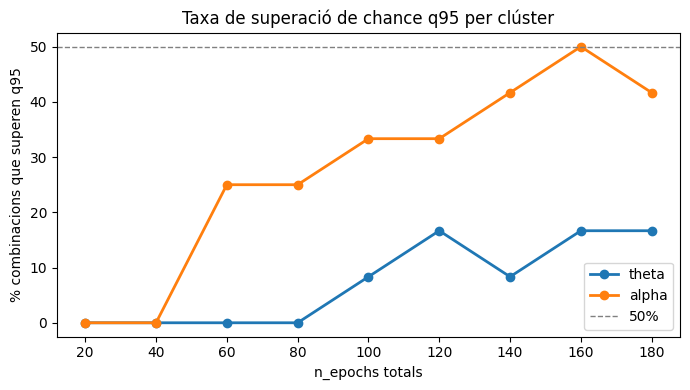

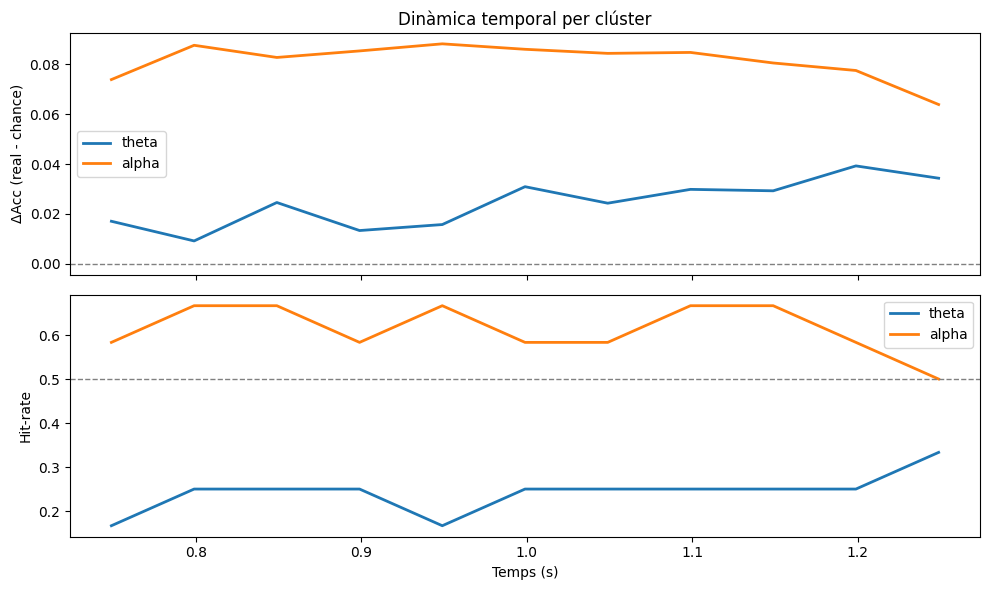


=== RESUM FINAL: Theta vs Alpha (Riemann) ===

theta:
  - Combinacions que superen q95: 8/108 (7.4%)
  - ΔAcc mitjà: 0.0236
  - Acc màxima: 0.6442

alpha:
  - Combinacions que superen q95: 30/108 (27.8%)
  - ΔAcc mitjà: 0.0732
  - Acc màxima: 0.6917



In [19]:
# 7d) Taxa de superació q95 per electròde
df_two["surpass_q95"] = (df_two["acc_real_mean"] > df_two["acc_chance_q95"]).astype(float)
surpass_tbl = (
    df_two.groupby(["electrode", "n_epochs_total"])["surpass_q95"]
    .mean()
    .unstack("electrode")
    .reindex(columns=target_electrodes)
    .sort_index()
)

fig, ax = plt.subplots(figsize=(7, 4))
for elec in target_electrodes:
    ax.plot(
        surpass_tbl.index,
        100 * surpass_tbl[elec].values,
        marker="o",
        linewidth=2,
        label=elec,
    )
ax.axhline(50, color="gray", linestyle="--", linewidth=1, label="50%")
ax.set_xlabel("n_epochs totals")
ax.set_ylabel("% combinacions que superen q95")
ax.set_title("Taxa de superació de chance q95 per clúster")
ax.legend()
plt.tight_layout()
plt.show()

# 7e) Dinàmica temporal (si el mapa temps×elèctrode està calculat)
needed = ["window_centers", "mean_delta_map", "hit_rate_map", "CHANNEL_MODE"]
if all(name in globals() for name in needed):
    ch_to_idx = {ch: i for i, ch in enumerate(CHANNEL_MODE)}

    valid_targets = [e for e in target_electrodes if e in ch_to_idx]
    if len(valid_targets) == 0:
        print("No hi ha clústers objectiu presents per la dinàmica temporal.")
    elif len(window_centers) < 2:
        print("Dinàmica temporal no informativa: només hi ha 1 finestra temporal.")
        plt.figure(figsize=(6, 3))
        bars = []
        for elec in valid_targets:
            ci = ch_to_idx[elec]
            bars.append(float(mean_delta_map[ci, 0]))
        plt.bar(valid_targets, bars)
        plt.axhline(0.0, color="gray", linestyle="--", linewidth=1)
        plt.ylabel("ΔAcc (única finestra)")
        plt.title("Resum temporal (1 finestra)")
        plt.tight_layout()
        plt.show()
    else:
        fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
        for elec in valid_targets:
            ci = ch_to_idx[elec]
            axes[0].plot(window_centers, mean_delta_map[ci], linewidth=2, label=elec)
            axes[1].plot(window_centers, hit_rate_map[ci], linewidth=2, label=elec)

        axes[0].axhline(0.0, color="gray", linestyle="--", linewidth=1)
        axes[0].set_ylabel("ΔAcc (real - chance)")
        axes[0].set_title("Dinàmica temporal per clúster")
        axes[0].legend()

        axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1)
        axes[1].set_ylabel("Hit-rate")
        axes[1].set_xlabel("Temps (s)")
        axes[1].legend()

        plt.tight_layout()
        plt.show()
else:
    print("Per mostrar la dinàmica temporal, executa primer les seccions 5 i 6.")

print("\n=== RESUM FINAL: Theta vs Alpha (Riemann) ===\n")
for elec in target_electrodes:
    dfe = df_two[df_two["electrode"] == elec]
    surpass = (dfe["acc_real_mean"] > dfe["acc_chance_q95"]).sum()
    total = len(dfe)
    avg_delta = dfe["delta_acc"].mean()
    max_acc = dfe["acc_real_mean"].max()
    print(f"{elec}:")
    print(f"  - Combinacions que superen q95: {surpass}/{total} ({100*surpass/total:.1f}%)")
    print(f"  - ΔAcc mitjà: {avg_delta:.4f}")
    print(f"  - Acc màxima: {max_acc:.4f}")
    print()

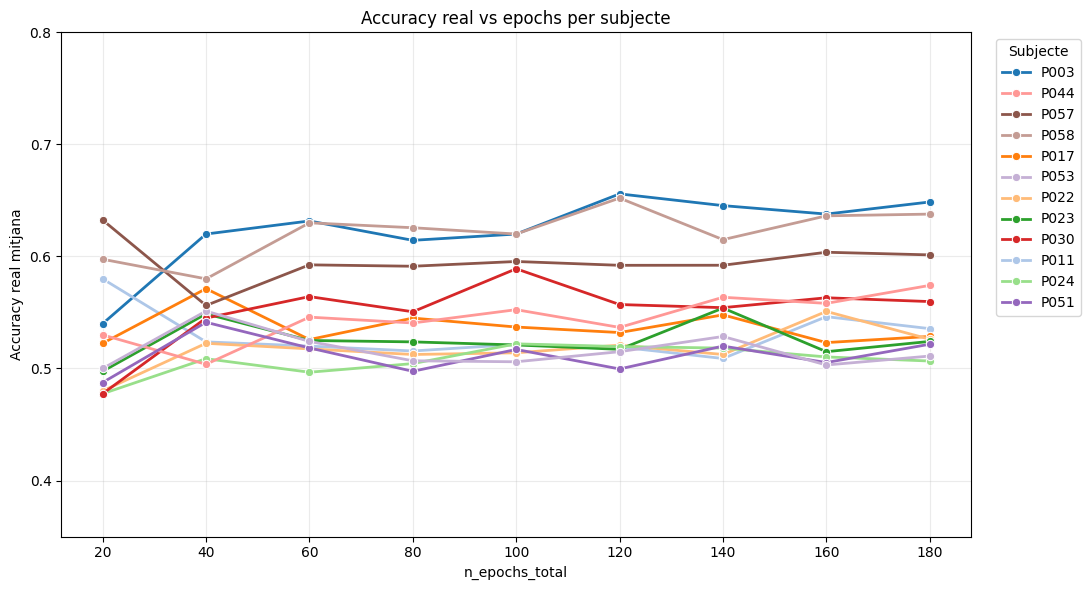

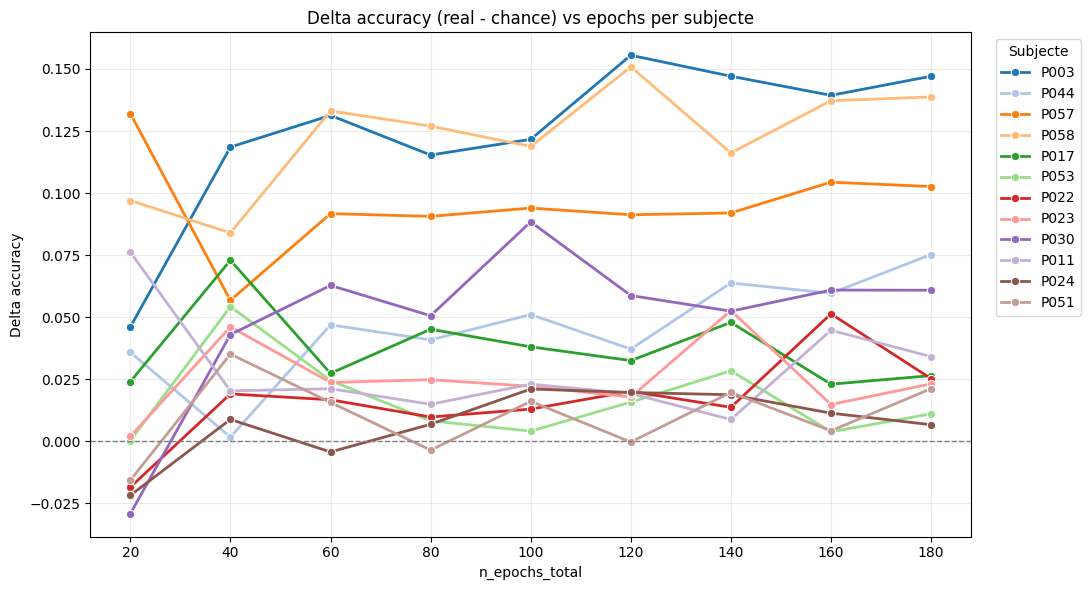

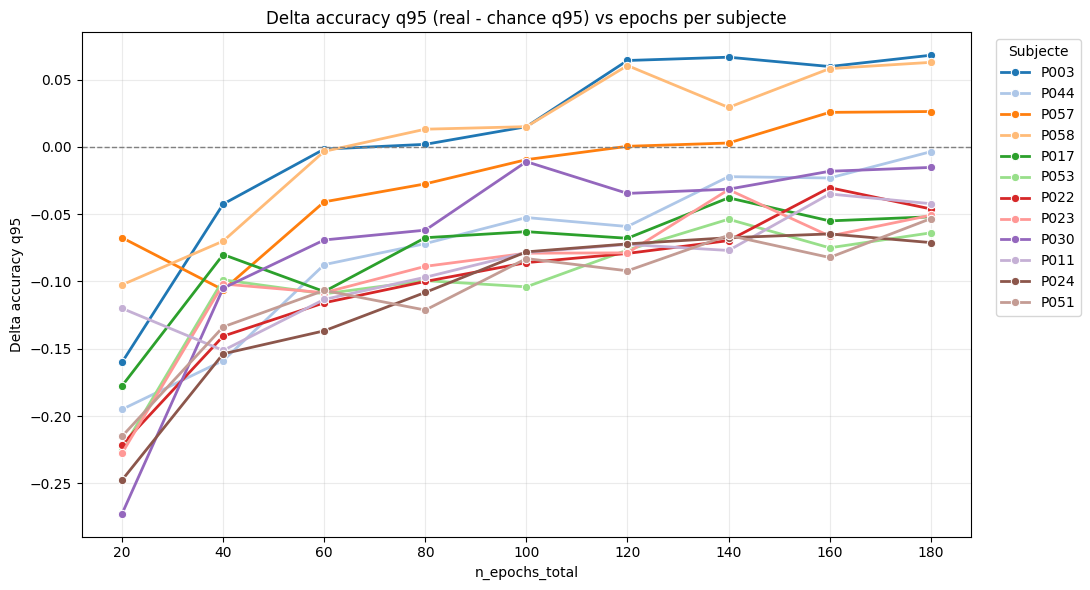

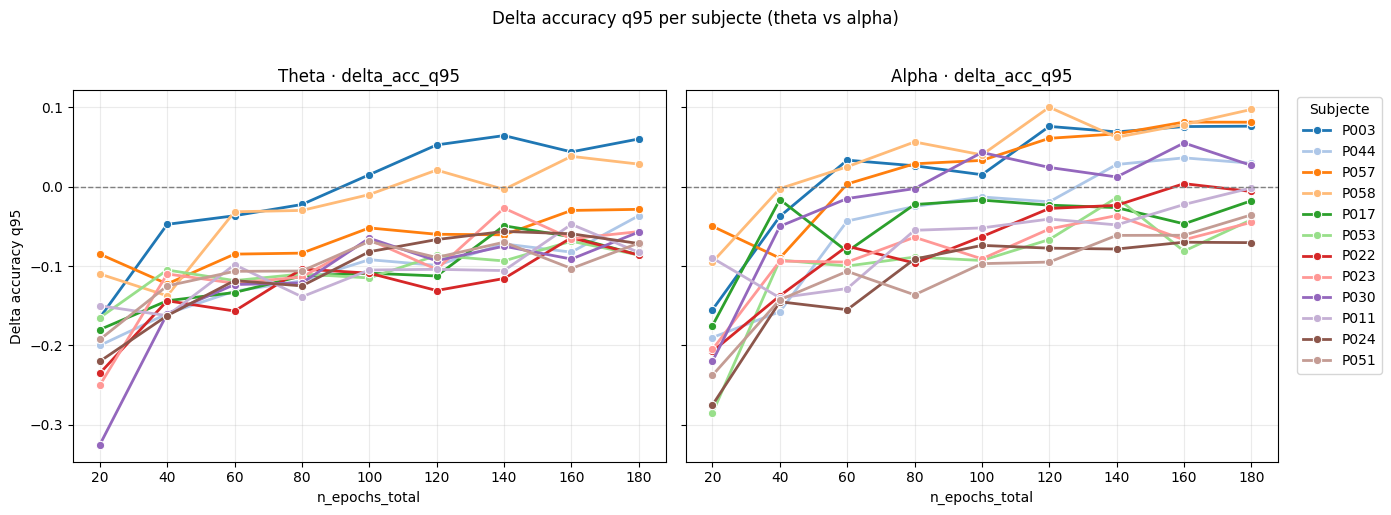

In [24]:
# Accuracy (real) segons nombre d'epochs, amb una línia per subjecte
df_subj_acc = (
    df_epochs.groupby(["subject", "n_epochs_total"], as_index=False)["acc_real_mean"]
    .mean()
    .sort_values(["subject", "n_epochs_total"])
)

plt.figure(figsize=(11, 6))
sns.lineplot(
    data=df_subj_acc,
    x="n_epochs_total",
    y="acc_real_mean",
    hue="subject",
    palette="tab20",
    marker="o",
    linewidth=2,
)

plt.title("Accuracy real vs epochs per subjecte")
plt.xlabel("n_epochs_total")
plt.ylabel("Accuracy real mitjana")
plt.ylim(0.35, 0.8)
plt.grid(alpha=0.25)
subject_order = [s for s in pd.unique(subj_list) if s in df_subj_acc["subject"].unique()]

# Reordena la llegenda del primer plot segons subj_list
fig1 = plt.gcf()
ax1 = plt.gca()
handles, labels = ax1.get_legend_handles_labels()
hmap = {lab: h for h, lab in zip(handles, labels)}
ordered_labels = [s for s in subject_order if s in hmap]
ordered_handles = [hmap[s] for s in ordered_labels]
ax1.legend(ordered_handles, ordered_labels, title="Subjecte", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Plot extra: delta accuracy vs epochs per subjecte
df_subj_delta = (
    df_epochs.groupby(["subject", "n_epochs_total"], as_index=False)["delta_acc"]
    .mean()
    .sort_values(["subject", "n_epochs_total"])
)

plt.figure(figsize=(11, 6))
sns.lineplot(
    data=df_subj_delta,
    x="n_epochs_total",
    y="delta_acc",
    hue="subject",
    hue_order=subject_order,
    palette="tab20",
    marker="o",
    linewidth=2,
)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.title("Delta accuracy (real - chance) vs epochs per subjecte")
plt.xlabel("n_epochs_total")
plt.ylabel("Delta accuracy")
plt.grid(alpha=0.25)
plt.legend(title="Subjecte", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Plot extra: delta accuracy q95 vs epochs per subjecte
df_subj_delta_q95 = (
    df_epochs.groupby(["subject", "n_epochs_total"], as_index=False)["delta_acc_q95"]
    .mean()
    .sort_values(["subject", "n_epochs_total"])
)

plt.figure(figsize=(11, 6))
sns.lineplot(
    data=df_subj_delta_q95,
    x="n_epochs_total",
    y="delta_acc_q95",
    hue="subject",
    hue_order=subject_order,
    palette="tab20",
    marker="o",
    linewidth=2,
)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.title("Delta accuracy q95 (real - chance q95) vs epochs per subjecte")
plt.xlabel("n_epochs_total")
plt.ylabel("Delta accuracy q95")
plt.grid(alpha=0.25)
plt.legend(title="Subjecte", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Plot extra: delta_acc_q95 separat per theta i alpha (2 subplots)
df_subj_delta_q95_elec = (
    df_epochs[df_epochs["electrode"].isin(["theta", "alpha"])]
    .groupby(["subject", "electrode", "n_epochs_total"], as_index=False)["delta_acc_q95"]
    .mean()
    .sort_values(["electrode", "subject", "n_epochs_total"])
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, elec in zip(axes, ["theta", "alpha"]):
    d = df_subj_delta_q95_elec[df_subj_delta_q95_elec["electrode"] == elec]
    sns.lineplot(
        data=d,
        x="n_epochs_total",
        y="delta_acc_q95",
        hue="subject",
        hue_order=subject_order,
        palette="tab20",
        marker="o",
        linewidth=2,
        ax=ax,
    )
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"{elec.capitalize()} · delta_acc_q95")
    ax.set_xlabel("n_epochs_total")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Delta accuracy q95")
if axes[0].legend_ is not None:
    axes[0].legend_.remove()
axes[1].legend(title="Subjecte", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.suptitle("Delta accuracy q95 per subjecte (theta vs alpha)", y=1.02)
plt.tight_layout()
plt.show()